# Exoplanet Transit Classification

**Machine learning experiments on Kepler light-curve data**

This notebook investigates how different model architectures classify stars as having a detected exoplanet or not. It compares a multilayer perceptron (MLP), a fully connected neural network, and a one-dimensional convolutional neural network (1D CNN).

## Project overview

The goal is to evaluate several machine-learning approaches for binary exoplanet classification using the provided Kepler-derived light-curve dataset. The workflow includes signal preprocessing, training-set class balancing, model training, and evaluation on a held-out test set.

### Models
- **MLP:** a scikit-learn baseline with one hidden layer.
- **Dense neural network:** a Keras feed-forward model.
- **1D CNN:** a convolutional model designed to learn local patterns across the ordered signal features.

The models are evaluated using test accuracy and confusion matrices. Because exoplanet-positive examples are rare, accuracy should be interpreted alongside the confusion matrices and class-specific metrics.

## 1. Data and approach

The dataset contains measurements represented as ordered light-curve features and a binary label. The original labels are converted from `1`/`2` to `0`/`1`, where `1` represents the positive exoplanet class after conversion.

The notebook uses the supplied training and test files. The test set remains separate from resampling: preprocessing transformations are fitted on training data and then applied to test data.

### Runtime note

Training neural networks is faster with a GPU. In Google Colab, select **Runtime → Change runtime type → T4 GPU** if one is available. CPU execution may take longer.

In [20]:
# Download the dataset files when they are not already present.
from pathlib import Path
import urllib.request

DATA_URL = (
    "https://storage.googleapis.com/inspirit-ai-data-bucket-1/Data/"
    "AI%20Scholars/Sessions%206%20-%2010%20(Projects)/Project%20-%20Planet%20Hunters/"
)
for filename in ("exoTrain.csv", "exoTest.csv"):
    if not Path(filename).exists():
        urllib.request.urlretrieve(DATA_URL + filename, filename)

# Core data and visualization libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Preprocessing and evaluation
from scipy.signal import savgol_filter
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import RobustScaler, normalize

# Neural-network libraries
import tensorflow as tf
from keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from keras.models import Sequential

# Load data and convert labels from 1/2 to 0/1.
df_train = pd.read_csv("exoTrain.csv")
df_test = pd.read_csv("exoTest.csv")
df_train["LABEL"] = df_train["LABEL"] - 1
df_test["LABEL"] = df_test["LABEL"] - 1

X_train = df_train.drop(columns="LABEL")
y_train = df_train["LABEL"]
X_test = df_test.drop(columns="LABEL")
y_test = df_test["LABEL"]


def plot_graphs(history, best):

  plt.figure(figsize=[10,4])
  # summarize history for accuracy
  plt.subplot(121)
  plt.plot(history.history['accuracy'])
  plt.plot(history.history['val_accuracy'])
  plt.title('model accuracy across training\n best accuracy of %.02f'%best[1])
  plt.ylabel('accuracy')
  plt.xlabel('epoch')
  plt.legend(['train', 'test'], loc='upper left')

  # summarize history for loss
  plt.subplot(122)
  plt.plot(history.history['loss'])
  plt.plot(history.history['val_loss'])
  plt.title('model loss across training\n best loss of %.02f'%best[0])
  plt.ylabel('loss')
  plt.xlabel('epoch')
  plt.legend(['train', 'test'], loc='upper left')
  plt.show()


In [18]:
from keras.models import Sequential

def analyze_results(model, X_train, y_train, X_test, y_test):
    """
    Helper function to help interpret and model performance.

    Args:
    model: estimator instance
    X_train: {array-like, sparse matrix} of shape (n_samples, n_features)
    Input values for model training.
    y_train : array-like of shape (n_samples,)
    Target values for model training.
    X_test: {array-like, sparse matrix} of shape (n_samples, n_features)
    Input values for model testing.
    y_test : array-like of shape (n_samples,)
    Target values for model testing.

    Returns:
    None
    """
    print("-------------------------------------------")
    print("Model Results")
    print("")
    print("Training:")
    if type(model) == Sequential:
      train_predictions = model.predict(X_train)
      train_predictions = (train_predictions > 0.5)
      cm = confusion_matrix(y_train, train_predictions)
      labels = [0, 1]
      df_cm = pd.DataFrame(cm,index = labels,columns = labels)
      fig = plt.figure()
      res = sns.heatmap(df_cm, annot=True,cmap='Blues', fmt='g')
      #plt.yticks([1.25, 3.75], labels,va='center')
      plt.title('Confusion Matrix - Training Data')
      plt.ylabel('True label')
      plt.xlabel('Predicted label')
      plt.show()
    else:
      plt.close()
      ConfusionMatrixDisplay.from_estimator(model,X_train,y_train)
      plt.show()

    print("Testing:")
    if type(model) == Sequential:
      test_predictions = model.predict(X_test)
      test_predictions = (test_predictions > 0.5)
      cm = confusion_matrix(y_test, test_predictions)
      labels = [0, 1]
      df_cm = pd.DataFrame(cm,index = labels,columns = labels)
      fig = plt.figure()
      res = sns.heatmap(df_cm, annot=True,cmap='Blues', fmt='g')
      #plt.yticks([1.25, 3.75], labels,va='center')
      plt.title('Confusion Matrix - Test Data')
      plt.ylabel('True label')
      plt.xlabel('Predicted label')
      plt.show()
    else:
      ConfusionMatrixDisplay.from_estimator(model,X_test,y_test)

## 2. Preprocessing

The training and test data are loaded into separate feature matrices and label vectors. The preprocessing pipeline applies a Fourier transform, Savitzky–Golay filtering, row normalization, and robust scaling. SMOTE is then applied **only to the training data** to address class imbalance.

These transformations are retained as experimental choices for this project; their impact should be assessed by comparing results against simpler preprocessing baselines.

In [7]:
#@title Run this code to preprocess data
# Helper functions that we can run for the three augmentation functions that will be used, but not explroed in depth

def smote(a,b):
    model = SMOTE()
    X,y = model.fit_resample(a, b)
    return X,y

def savgol(df1,df2):
    x = savgol_filter(df1,21,4,deriv=0)
    y = savgol_filter(df2,21,4,deriv=0)
    return x,y

def fourier(df1,df2):
    X_train = np.abs(np.fft.fft(df1, axis=1))
    X_test = np.abs(np.fft.fft(df2, axis=1))
    return X_train,X_test

def norm(df1,df2):
    X_train = normalize(df1)
    X_test = normalize(df2)
    return X_train,X_test

def robust(df1,df2):
    scaler = RobustScaler()
    X_train = scaler.fit_transform(df1)
    X_test = scaler.transform(df2)
    return X_train,X_test

fourier_X_train, fourier_X_test = fourier(X_train, X_test)
savgol_X_train, savgol_X_test = savgol(fourier_X_train, fourier_X_test)
norm_X_train, norm_X_test = norm(savgol_X_train,savgol_X_test)
robust_X_train, robust_X_test = robust(norm_X_train, norm_X_test)
smote_X_train,smote_y_train = smote(robust_X_train, y_train)

# Here we're adding the generated, augmented data onto the testing data
# aug_X_train, new_X_test_data, aug_y_train, new_y_test_data = train_test_split(smote_X_train, smote_y_train, test_size=0.3)
# aug_X_test = np.concatenate((robust_X_test, new_X_test_data), axis=0)
# aug_y_test = np.concatenate((y_test, new_y_test_data), axis=0)

The processed variables used below are:

- `smote_X_train`, `smote_y_train`: preprocessed and resampled training data.
- `robust_X_test`, `y_test`: preprocessed, unresampled test data.

Keeping the test set unresampled preserves the original class distribution for evaluation.

## 3. Model A — Multilayer perceptron

The first model is a scikit-learn `MLPClassifier` with one hidden layer of 10 units. It provides a compact neural-network baseline for comparison with the Keras models.

### Model configuration

The model uses a fixed random seed for reproducibility and a maximum of 300 training iterations.

In [8]:
# MLP baseline: one hidden layer with 10 units.
model = MLPClassifier(
    hidden_layer_sizes=(10,),
    random_state=1,
    max_iter=300,
)


### Train and evaluate

Fit the MLP on the resampled training set, then evaluate it on the untouched test set. The training score is included as a diagnostic; the test score is the more relevant estimate of generalization.

Training accuracy: 0.9997
Test accuracy:     0.9930


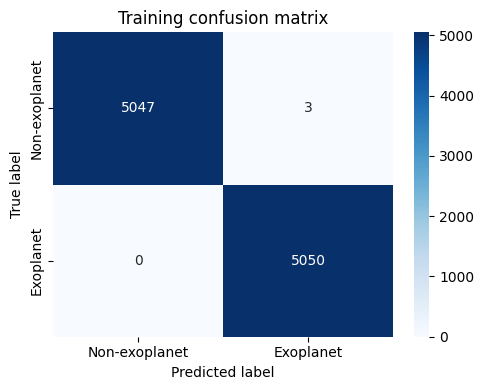

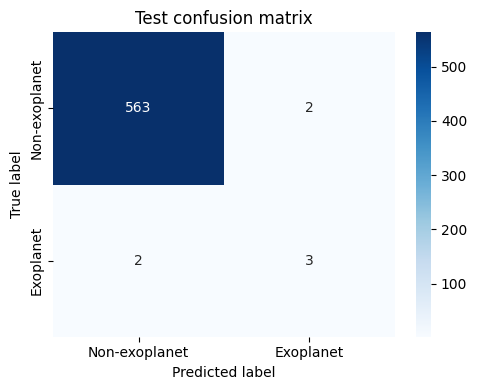

               precision    recall  f1-score   support

Non-exoplanet       1.00      1.00      1.00       565
    Exoplanet       0.60      0.60      0.60         5

     accuracy                           0.99       570
    macro avg       0.80      0.80      0.80       570
 weighted avg       0.99      0.99      0.99       570



In [9]:
model.fit(smote_X_train,smote_y_train)
train_pred = model.predict(smote_X_train)
test_pred = model.predict(robust_X_test)
print(accuracy_score(smote_y_train,train_pred))
print(accuracy_score(y_test,test_pred))

analyze_results(model,smote_X_train,smote_y_train,robust_X_test,y_test)

### Interpretation

Review the test accuracy and confusion matrix. In particular, consider how many positive examples are detected and how many are missed. A high overall accuracy can be misleading when the positive class is rare.

### Further experiment: MLP

To extend this experiment, vary the number of hidden layers and units, and compare results using the same test set. You can also compare the processed features with the original features. Record the configuration and metrics for each run so the comparisons remain reproducible.

## 4. Model B — Fully connected neural network

This model uses Keras to build a feed-forward neural network with a ReLU hidden layer and a sigmoid output. The sigmoid output produces a probability-like score for the positive class, making binary cross-entropy an appropriate loss function.

In [22]:
# Fully connected neural network.
model = Sequential([
    Dense(10, activation="relu", input_shape=(X_train.shape[1],)),
    Dense(1, activation="sigmoid"),
])
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Architecture summary

Inspect the model summary to confirm the input dimensions and the number of trainable parameters.

In [23]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 10)             │        31,980 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,991 (124.96 KB)

 Trainable params: 31,991 (124.96 KB)

 Non-trainable params: 0 (0.00 B)

### Train the network

The network is trained for up to 20 epochs with batches of 64 samples. The held-out test set is supplied as validation data so that loss and accuracy can be monitored during training. For a more rigorous final evaluation, avoid using test-set results to repeatedly tune model choices.

In [24]:
history = model.fit(
    smote_X_train,
    smote_y_train,
    batch_size=64,
    epochs=20,
    verbose=1,
    validation_data=(robust_X_test, y_test),
    shuffle=True,
)


Epoch 1/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9332 - loss: 0.1722 - val_accuracy: 0.9737 - val_loss: 0.1177
Epoch 2/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9896 - loss: 0.0394 - val_accuracy: 0.9877 - val_loss: 0.0807
Epoch 3/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9887 - loss: 0.0369 - val_accuracy: 0.9877 - val_loss: 0.1075
Epoch 4/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9853 - loss: 0.0440 - val_accuracy: 0.9895 - val_loss: 0.0892
Epoch 5/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9949 - loss: 0.0185 - val_accuracy: 0.9930 - val_loss: 0.0900
Epoch 6/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9947 - loss: 0.0168 - val_accuracy: 0.9912 - val_loss: 0.1054
Epoch 7/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9967 - loss: 0.0120 - val_accuracy: 0.9912 - val_loss: 0.1097
Epoch 8/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9952 - loss: 0.0137 - val_accuracy: 0.

### Training history and evaluation

The plots show training and validation accuracy and loss across epochs. The confusion matrices provide a complementary view of class-specific errors.

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9930 - loss: 0.1361 


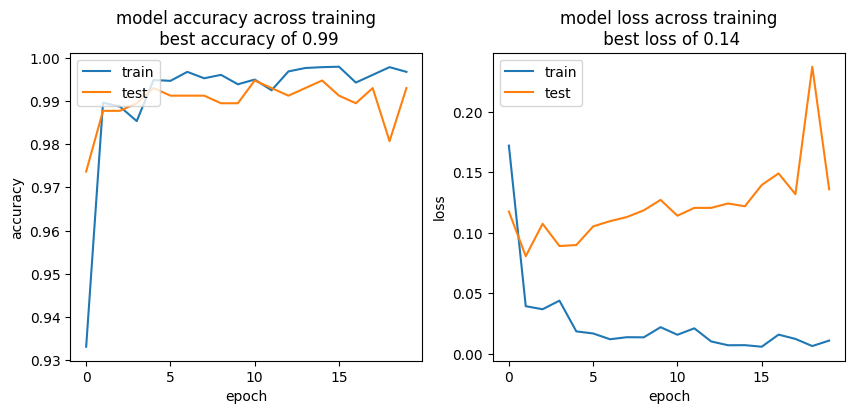

-------------------------------------------
Model Results

Training:
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


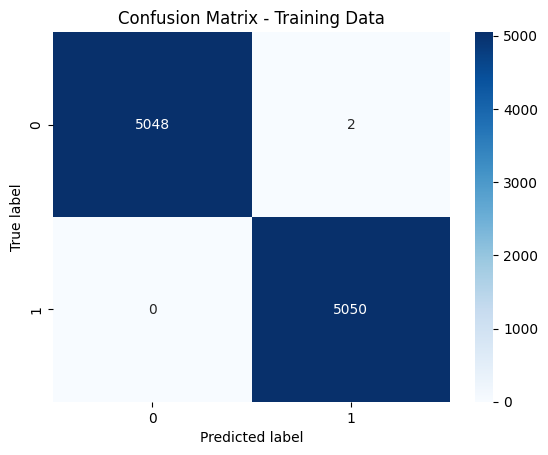

Testing:
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


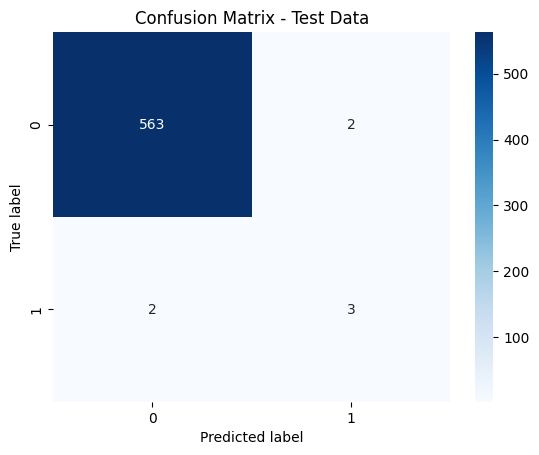

In [25]:
performance = model.evaluate(robust_X_test, y_test, batch_size=64)
plot_graphs(history, performance)
analyze_results(model=model,X_train = smote_X_train,y_train=smote_y_train,X_test=robust_X_test,y_test=y_test)

### Further experiment: dense network

Try changing the number of hidden layers or units. Compare the resulting test metrics with the baseline while keeping the preprocessing and evaluation procedure consistent.

## 5. Model C — One-dimensional convolutional neural network

A fully connected network can be sensitive to where patterns appear in an input sequence. A 1D CNN applies learned filters across adjacent features, allowing it to detect local patterns at different positions. This experiment reshapes each sample to `(number_of_features, 1)` so it can be processed by `Conv1D` layers.

### Prepare the CNN inputs

The reshape operation changes the array dimensions without changing the underlying values. Both the resampled training features and the preprocessed test features are reshaped for the CNN. The original, unprocessed features are also reshaped for optional comparisons.

In [14]:
# Reshape each sample to (features, channels) for Conv1D.
cnn_smote_X_train = np.expand_dims(smote_X_train, axis=-1)
cnn_smote_y_train = np.asarray(smote_y_train)

cnn_preprocess_X_test = np.expand_dims(robust_X_test, axis=-1)
cnn_preprocess_y_test = np.asarray(y_test)

# Original features, reshaped for optional baseline comparisons.
cnn_X_train = np.expand_dims(X_train.to_numpy(), axis=-1)
cnn_y_train = np.asarray(y_train)
cnn_X_test = np.expand_dims(X_test.to_numpy(), axis=-1)
cnn_y_test = np.asarray(y_test)


### Verify input dimensions

The expected feature-array shape is `(samples, features, 1)`, while the label arrays remain one-dimensional.

In [15]:
print("Resampled training features:", cnn_smote_X_train.shape)
print("Training labels:", cnn_smote_y_train.shape)
print("Preprocessed test features:", cnn_preprocess_X_test.shape)
print("Test labels:", cnn_preprocess_y_test.shape)


Resampled training features: (10100, 3197, 1)
Training labels: (10100,)
Preprocessed test features: (570, 3197, 1)
Test labels: (570,)


### CNN architecture

The network uses two convolutional layers, each followed by max pooling, then a flattening layer and a sigmoid output. The architecture is intentionally compact to provide a baseline for experiments with deeper networks, different filter counts, or dropout.

In [16]:
# Compact one-dimensional CNN.
model = Sequential([
    Conv1D(8, kernel_size=5, activation="relu", padding="same",
           input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(pool_size=4, strides=4, padding="same"),
    Conv1D(16, kernel_size=3, activation="relu", padding="same"),
    MaxPooling1D(pool_size=4, strides=4, padding="same"),
    Flatten(),
    Dense(1, activation="sigmoid"),
])
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Train the CNN

Train using the reshaped, resampled training set and monitor performance on the preprocessed test set.

In [17]:
history = model.fit(
    cnn_smote_X_train,
    cnn_smote_y_train,
    batch_size=64,
    epochs=20,
    verbose=1,
    validation_data=(cnn_preprocess_X_test, cnn_preprocess_y_test),
    shuffle=True,
)


Epoch 1/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 14s 80ms/step - accuracy: 0.8913 - loss: 0.2669 - val_accuracy: 0.9877 - val_loss: 0.0820
Epoch 2/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.9876 - loss: 0.0569 - val_accuracy: 0.9860 - val_loss: 0.0808
Epoch 3/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 12s 76ms/step - accuracy: 0.9949 - loss: 0.0287 - val_accuracy: 0.9860 - val_loss: 0.0623
Epoch 4/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 29s 132ms/step - accuracy: 0.9958 - loss: 0.0184 - val_accuracy: 0.9860 - val_loss: 0.0643
Epoch 5/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 22s 136ms/step - accuracy: 0.9973 - loss: 0.0131 - val_accuracy: 0.9930 - val_loss: 0.0420
Epoch 6/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - accuracy: 0.9977 - loss: 0.0098 - val_accuracy: 0.9930 - val_loss: 0.0463
Epoch 7/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 14s 71ms/step - accuracy: 0.9975 - loss: 0.0077 - val_accuracy: 0.9965 - val_loss: 0.0364
Epoch 8/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 25s 101ms/step - accuracy: 0.9987 - loss: 0.007

### Evaluate the CNN

Compare the CNN's test results with those of the MLP and dense network. Consider both overall accuracy and the distribution of false positives and false negatives.

-------------------------------------------
Model Results

Training:
316/316 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step


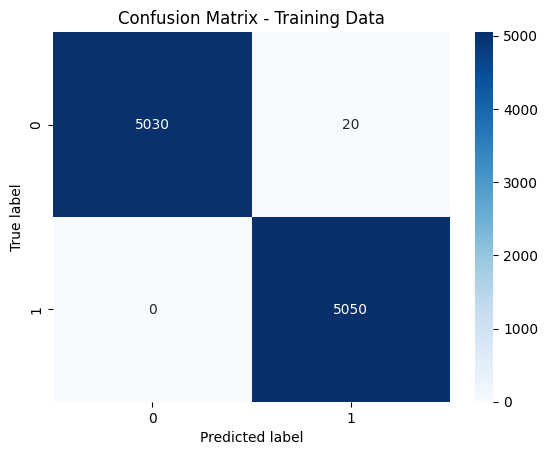

Testing:
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


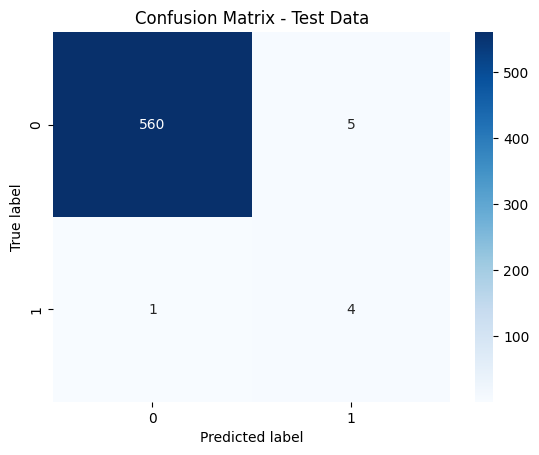

In [19]:
analyze_results(model,X_train = cnn_smote_X_train,y_train=cnn_smote_y_train,X_test=cnn_preprocess_X_test,y_test=cnn_preprocess_y_test)

In [ ]:
# Optional: save the trained CNN to Google Drive (Google Colab only).
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")
model_path = Path("/content/drive/MyDrive/exoplanet_cnn.keras")
model.save(model_path)
print(f"Model saved to: {model_path}")


### Further experiment: CNN

Explore different filter counts, kernel sizes, pooling settings, and dropout. Keep a record of each model configuration and its test metrics.

## 6. Discussion and next steps

## Summary

This notebook compares three neural-network approaches for classifying exoplanet candidates from light-curve features. The results should be interpreted in the context of class imbalance: detecting the positive class reliably is important, and accuracy alone does not capture that performance.

A useful next step is to consolidate the metrics from all models into a comparison table and investigate precision, recall, and F1 score for the positive class. Any conclusions should be based on the measured results from the completed runs.

### Additional experiments

Potential extensions include comparing preprocessing strategies, testing alternative model architectures, and evaluating how class balancing affects performance. Change one factor at a time and document the settings so each experiment can be reproduced.